In [4]:
options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

In [8]:
library('tidymodels')

gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


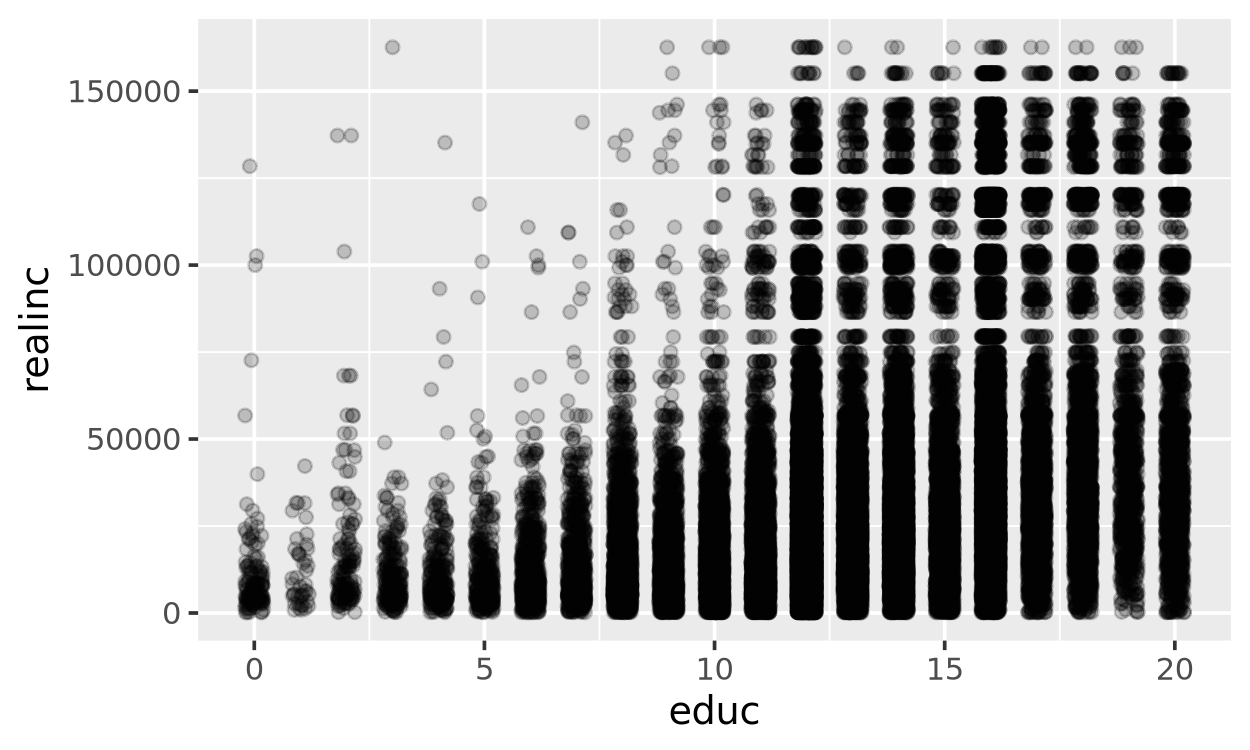

In [11]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.2, position = position_jitter(width = 0.2, height = 0.2))

In [15]:
set.seed(123)
n_combos = 250

params = tibble(
    .rep = 1:n_combos,
    intercept = runif(n_combos, -50000, 50000),
    slope = runif(n_combos, 0, 5000)
)

params |> glimpse()

Rows: 250
Columns: 3
$ .rep      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> -21242.248, 28830.514, -9102.308, 38301.740, 44046.728, -454…
$ slope     <dbl> 1286.08373, 1108.93967, 2965.22826, 1337.60716, 2655.35199, …


Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


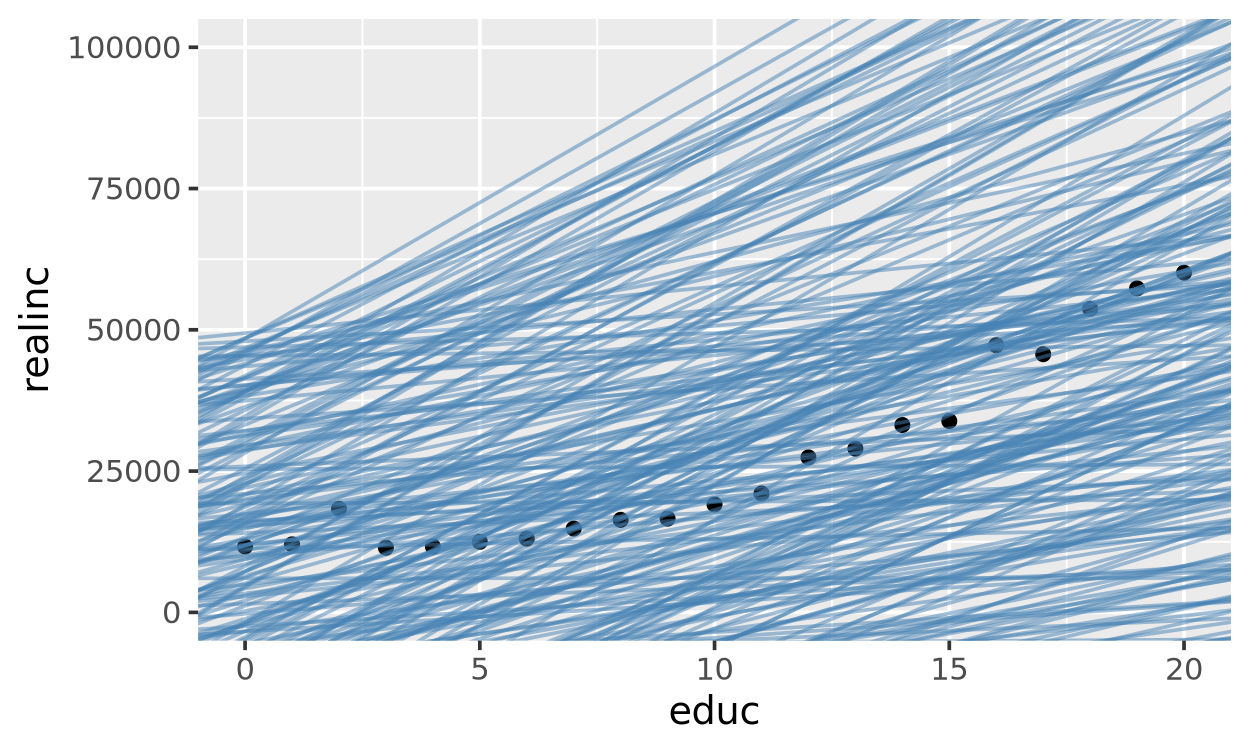

In [19]:
gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc, na.rm = TRUE)) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point() +
    geom_abline(
        data = params,
        aes(intercept = intercept, slope = slope),
        alpha = 0.5, color = 'steelblue'
    ) +
    coord_cartesian(ylim = c(0, 100000))

Steps for creating a model:

1. Pick the model form: a linear model

$$\text{realinc} = \text{intercept} + \text{slope} \cdot \text{educ}$$

2. Design a way to evaluate different model parameters.
3. Optimize our paramater values.

In [21]:
rmse_fn = function(intercept, slope, data = gss) {
    pred = intercept + slope * data$educ
    resid = data$realinc - pred # short for residual
    sqrt(mean(resid^2, na.rm = TRUE))
}

rmse_fn(intercept = 0, slope = 2500)

[1] 28504.88

In [20]:
params = params |>
    rowwise() |>
    mutate(rmse = rmse_fn(intercept, slope)) |>
    ungroup()

params |> glimpse()

Rows: 250
Columns: 4
$ .rep      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 1…
$ intercept <dbl> -21242.248, 28830.514, -9102.308, 38301.740, 44046.728, -454…
$ slope     <dbl> 1286.08373, 1108.93967, 2965.22826, 1337.60716, 2655.35199, …
$ rmse      <dbl> 47049.63, 31296.36, 28490.15, 37355.48, 54436.77, 38692.53, …


Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


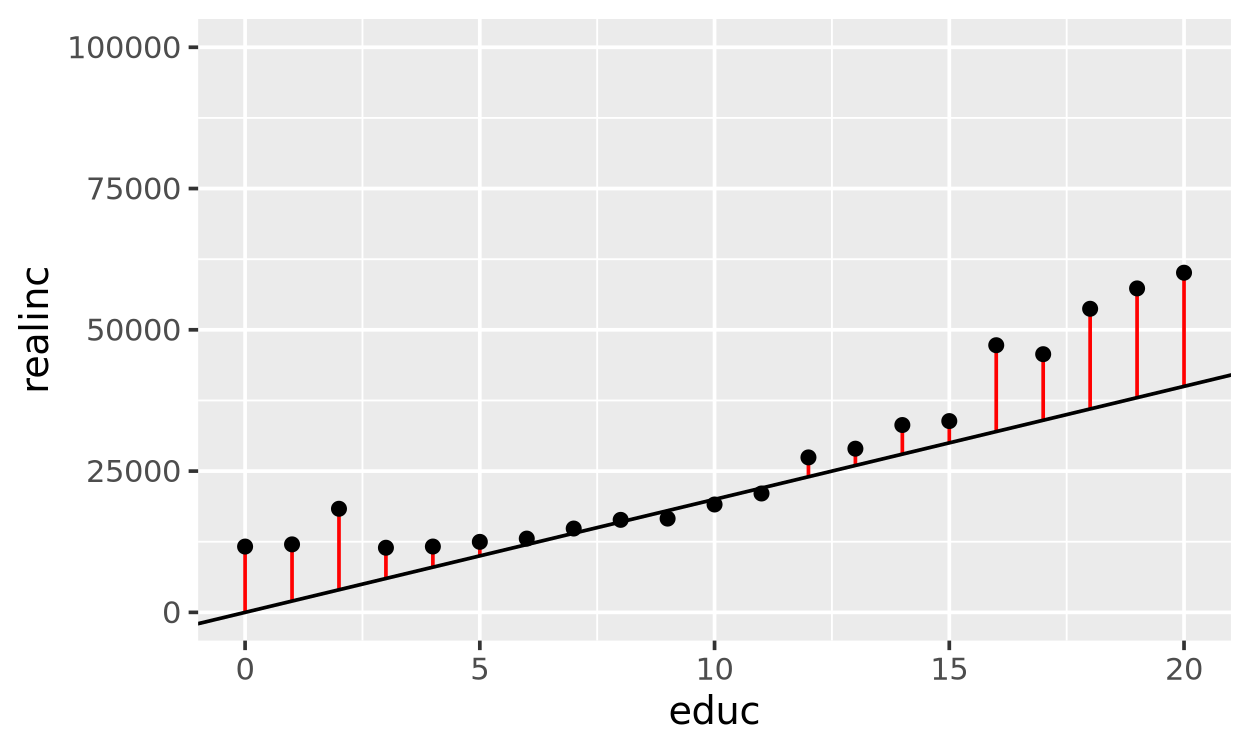

In [40]:
model_intercept = 0
model_slope = 2000

gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc, na.rm = TRUE)) |>
    mutate(pred = model_intercept + model_slope * educ) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_segment(aes(xend = educ, yend = pred), color = 'red') +
    geom_point() +
    geom_abline(intercept = model_intercept, slope = model_slope) +
    coord_cartesian(ylim = c(0, 100000))

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


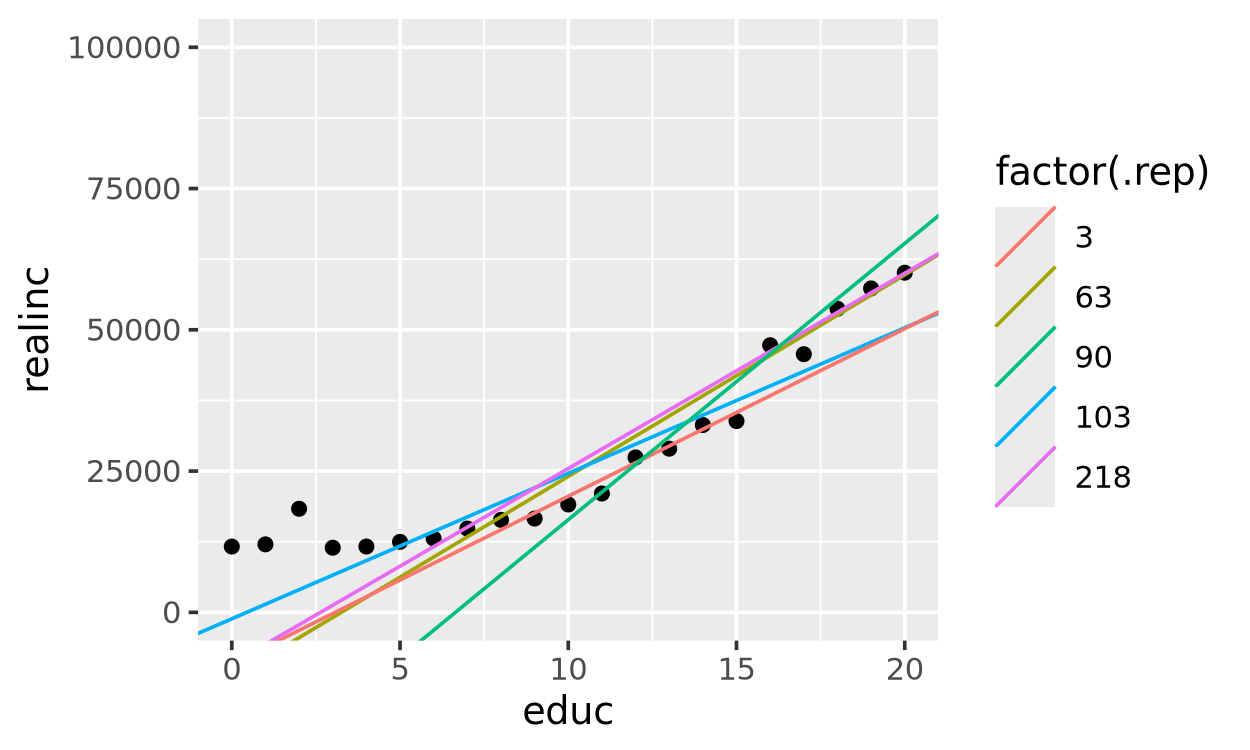

In [44]:
best5 = params |> slice_min(rmse, n = 5)

gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc, na.rm = TRUE)) |>
    ggplot(aes(x = educ, y = realinc)) +
    geom_point() +
    geom_abline(
        data = best5,
        aes(intercept = intercept, slope = slope, color = factor(.rep))
    ) +
    coord_cartesian(ylim = c(0, 100000))